# Imports

In [1]:
import os
import numpy as np
from numpy import deg2rad
import pandas as pd
import json
import gzip
from tqdm.notebook import trange
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from pyroomacoustics.directivities import Rotation3D
import arctic
from tools import *

# Usage example

## Load example room configuration

In [2]:
with gzip.open(f"simulated_room_example.json.gz", "rt", encoding="utf-8") as f:
    room_data = json.load(f)

room_dim = room_data["geometry"]["room_dim"]
src_pos = room_data["geometry"]["pos_src"]
img1 = np.array(room_data["observations"]["img1"])
img2 = np.array(room_data["observations"]["img2"])
t1 = np.array(room_data["ground_truth"]["t1"])
t2 = np.array(room_data["ground_truth"]["t2"])
R_true = np.array(room_data["ground_truth"]["R21"])
t_true = np.array(room_data["ground_truth"]["t21"])
matches_true = np.array(room_data["ground_truth"]["matches_pairs"])

plot_room_with_sources(
    room_dim=room_dim,
    source_pos=src_pos,
    mic_positions=[t1, t2],
    image_sources=None,  # Set to None to not plot image sources
    point_size=5,
    zoom=1.0,
    show_background=True
)
plot_point_clouds(img1, img2, labels=("Array 1", "Array 2"))

## Run ARCTIC

In [3]:
hyperparameters = {
    "epsilon": 0.8,
    "alpha": 1.0,
    "n_iter": 1000,
}

R, t, matches, triangle_vertices = arctic.arctic(
    img1.T, img2.T,
    epsilon=hyperparameters["epsilon"],
    alpha=hyperparameters["alpha"],
    n_iter=hyperparameters["n_iter"]
)

PERFORMANCE METRICS
    Geodesic Distance:                        2.936°
    Angular Error:                            1.032°
    Inter-Array Distance Error:               0.017 m
    Euclidean Distance Error:                 0.090 m
    Number of matches found:                  14 out of 18 possible matches
    Number of correct matches:                14


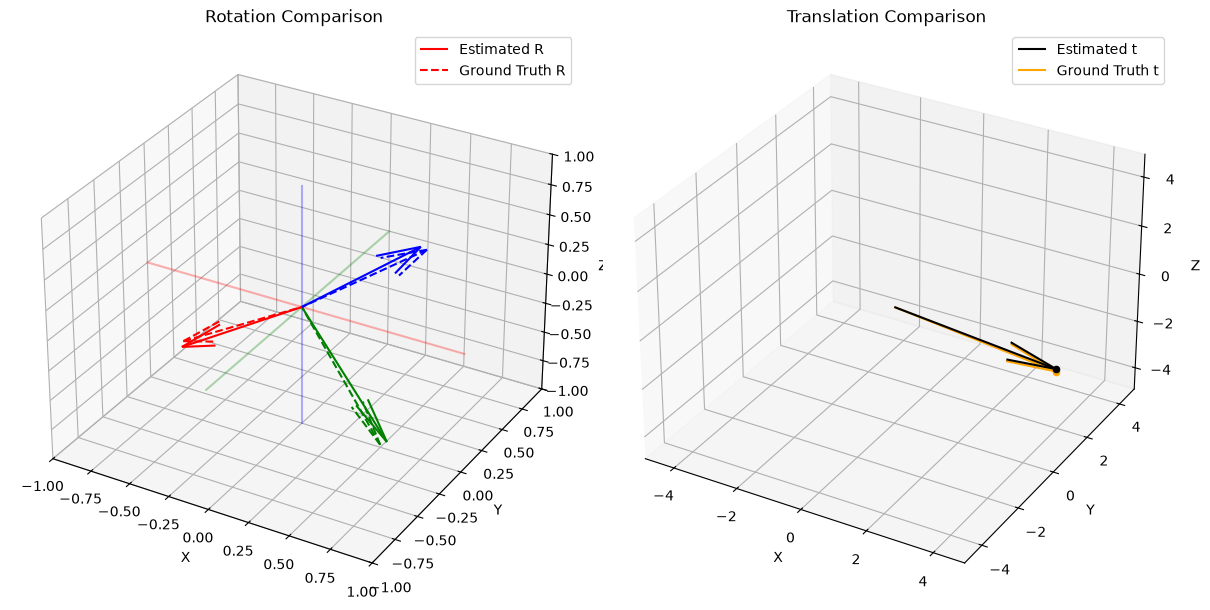

In [14]:
print_performance(R, R_true, t, t_true, matches, matches_true)
plot_transform_comparison(R, R_true, t, t_true, labels=["Estimated R", "Ground Truth R", "Estimated t", "Ground Truth t"], scale=1.0)

# Simulated data

## Dataset generation

Run the following cells to generate a dataset of simulated configurations following the procedure presented in the paper.

In [ ]:
# Number of configurations to generate
N = 100

# Overwrite existing files?
overwrite = False

In [6]:
room_dim_bounds = [(3, 7),  # x dimension
                   (3, 7),  # y dimension
                   (2.1, 5)]  # z dimension
min_dist_from_walls = 0.5
min_dist_src_mics = 1.0

for n in range(N):

    if not overwrite and os.path.exists(f"simulated_data/room_{n}.json.gz"):
        continue

    room_dim = tuple(np.random.uniform(low, high) for low, high in room_dim_bounds)
    src_pos = (np.random.uniform(min_dist_from_walls, room_dim[0]-min_dist_from_walls),
               np.random.uniform(min_dist_from_walls, room_dim[1]-min_dist_from_walls),
               np.random.uniform(min_dist_from_walls, room_dim[2]-min_dist_from_walls))

    t1, t2 = src_pos, src_pos  # Initialize t1 and t2 to src_pos to enter the while loops
    while np.linalg.norm(np.array(src_pos) - np.array(t1)) < min_dist_src_mics:
        t1 = [np.random.uniform(min_dist_from_walls, room_dim[0]-min_dist_from_walls),
              np.random.uniform(min_dist_from_walls, room_dim[1]-min_dist_from_walls),
              np.random.uniform(min_dist_from_walls, room_dim[2]-min_dist_from_walls)]

    while np.linalg.norm(np.array(src_pos) - np.array(t2)) < min_dist_src_mics:
        t2 = [np.random.uniform(min_dist_from_walls, room_dim[0]-min_dist_from_walls),
              np.random.uniform(min_dist_from_walls, room_dim[1]-min_dist_from_walls),
              np.random.uniform(min_dist_from_walls, room_dim[2]-min_dist_from_walls)]

    R1 = get_rotation_matrix(deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)))

    R2 = get_rotation_matrix(deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)))

    # Generate the point clouds and get the ground truth matches
    img1, img2, removed_indices_1, removed_indices_2, matches_pairs, img_sources_perfect = generate_point_clouds(
        room_dim=room_dim,
        src_pos=src_pos,
        R1=R1,
        t1=t1,
        R2=R2,
        t2=t2,
        max_order_ism=4,
        sigma_noise=1.0,
        base_ratio_1=0.05,
        max_ratio_1=0.6,
        base_ratio_2=0.05,
        max_ratio_2=0.7,
        max_distance_to_mics=12,
    )

    matches_pairs_json = [
        [int(a), int(b)]
        for a, b in matches_pairs
    ]

    R21, t21 = compute_relative_transformation(R1, t1, R2, t2)

    # Store all calculated values for this configuration in a dict
    room_data = {
        "max_order_ism": 4,
        "geometry": {
            "room_dim": room_dim,
            "pos_src": src_pos,
        },
        "ground_truth": {
            "R1": R1.tolist(),
            "t1": t1,
            "R2": R2.tolist(),
            "t2": t2,
            "R21": R21.tolist(),
            "t21": t21.tolist(),
            "matches_pairs": matches_pairs_json,
        },
        "observations": {
            "img1": img1.tolist(),
            "img2": img2.tolist(),
            "removed_indices_1": removed_indices_1.tolist(),
            "removed_indices_2": removed_indices_2.tolist(),
        },
    }
    
    # Write the contents of this dict to a file named with the number of the room
    os.makedirs("simulated_data", exist_ok=True)
    with gzip.open("simulated_data/room_{:d}.json.gz".format(n), "wt", encoding="utf-8") as f:
        json.dump(room_data, f)

## Run ARCTIC

In [7]:
def compute_alignment_dataset(
        hyperparameters,
        rooms_range=[0, 100],
):

    geodesic_distances = []
    angular_errors = []
    inter_array_distance_errors = []
    euclidean_distance_errors = []
    nb_matches = []
    matches_precisions = []
    matches_recalls = []

    nb_rooms = rooms_range[1] - rooms_range[0]

    for i in trange(nb_rooms, desc="Processing rooms", unit="room"):
        n = i + rooms_range[0]

        # Load room data
        with gzip.open(f"simulated_data/room_{n}.json.gz", "rt", encoding="utf-8") as f:
            room_data = json.load(f)

        img1 = np.array(room_data["observations"]["img1"])
        img2 = np.array(room_data["observations"]["img2"])
        R_true = np.array(room_data["ground_truth"]["R21"])
        t_true = np.array(room_data["ground_truth"]["t21"])
        matches_true = np.array(room_data["ground_truth"]["matches_pairs"])

        try:
            R, t, matches, _ = arctic.arctic(
                img1.T, img2.T,
                epsilon=hyperparameters["epsilon"],
                alpha=hyperparameters["alpha"],
                n_iter=hyperparameters["n_iter"]
            )

            metrics = compute_metrics(R, R_true, t, t_true)

            geodesic_distances.append(metrics["geodesic_distance"])
            angular_errors.append(metrics["angular_error"])
            euclidean_distance_errors.append(metrics["euclidean_distance_error"])
            inter_array_distance_errors.append(metrics["inter_array_distance_error"])

            nb_matches.append(len(matches))
            precision = sum(1 for (i, j) in matches if (i, j) in matches_true) / len(matches) if len(matches) > 0 else 0 #Precision = TP/(TP+FP)
            recall = sum(1 for (i, j) in matches if (i, j) in matches_true) / len(matches_true) if len(matches_true) > 0 else 0 #Recall = TP/(TP+FN)
            matches_precisions.append(precision)
            matches_recalls.append(recall)

        except Exception as e:
            print(f"Error processing room {n}: {e}")
            geodesic_distances.append(np.nan)
            angular_errors.append(np.nan)
            euclidean_distance_errors.append(np.nan)
            inter_array_distance_errors.append(np.nan)
            nb_matches.append(np.nan)
            matches_precisions.append(np.nan)
            matches_recalls.append(np.nan)
            continue

    data = {
        "nb_rooms": nb_rooms,
        "hyperparameters": {
            "n_iter": hyperparameters["n_iter"],
            "epsilon": hyperparameters["epsilon"],
            "alpha": hyperparameters["alpha"],
        },
        "geodesic_distances": geodesic_distances,
        "angular_errors": angular_errors,
        "euclidean_distance_errors": euclidean_distance_errors,
        "inter_array_distance_errors": inter_array_distance_errors,
        "nb_matches": nb_matches,
        "matches_precisions": matches_precisions,
        "matches_recalls": matches_recalls,
    }

    return data

In [8]:
hyperparameters = {
    "n_iter": 1000,
    "epsilon": 0.8,
    "alpha": 1.0,
}

data = compute_alignment_dataset(
    hyperparameters=hyperparameters,
    rooms_range=[0, 100],
)

Processing rooms:   0%|          | 0/100 [00:00<?, ?room/s]

In [9]:
print_performance_multi(data, geodesic_distance_max=15, euclidean_distance_error_max=0.5)

PERFORMANCE METRICS ON 100 ROOMS
    Number of correct alignments:             94 (94.00%)
    Number of incorrect alignments:           6 (6.00%)
    Number of flipped alignments:             4 (4.00%)
    Average number of matches:                20.47
    Average match precision:                  97.97%
    Average match recall:                     68.27%

For the 94 correct alignments only (geodesic distance < 15°, euclidean distance error < 0.5 m):
    Average Geodesic Distance:               2.625°
    Average Angular Error:                   2.117°
    Average Inter-Array Distance Error:      0.040 m
    Average Euclidean Distance Error:        0.088 m


# Real data from ARPEGE dataset

Image source point clouds were extracted following the pipeline presented in the paper. The following figure schematically represents this pipeline.

![](rsc/proposed_pipeline.svg)

In [10]:
def compute_alignment_dataset_real(
        hyperparameters,
):

    geodesic_distances = []
    angular_errors = []
    inter_array_distance_errors = []
    euclidean_distance_errors = []
    nb_matches = []

    # Load ARPEGE annotations
    df_annotation = pd.read_pickle("real_data/annotation_ARPEGE.pkl")

    # Build pairs of measurements
    pairs = []

    # First 8 files: consecutive pairs
    for n in range(1, 9, 2): #9
        pairs.append((n, n + 1))

    # Remaining files: groups of 4
    for start in range(9, 73, 4):
        pairs.append((start, start + 3))      # (9,12), (13,16), ...
        pairs.append((start + 1, start + 2))  # (10,11), (14,15), ...


    # Point cloud loader
    def load_point_cloud(mes):
        data = np.load(f'real_data/clouds/mes_{mes}_best.npz')
        img = np.array(data['x']).T
        amplitudes = np.array(data['a'])

        idx_a = [i for i in range(len(amplitudes)) if amplitudes[i] > 5]
        img = img[:, idx_a]

        with gzip.open(f'real_data/raw/room_{mes}_0.json.gz', 'r') as f:
            content = json.load(f)
            data = content["geometry"]
            t = np.array(data["pos_mics"])

            name = data["name"]
            mask = (df_annotation["type"] == 'RIR')  & (df_annotation["mic_id"] == 32)
            mask_2 = (df_annotation["room"] == name[0]) & (df_annotation["pos_num"] == name[1])
            angles = df_annotation[mask & mask_2]["angle_zyz_em32"].values[0]
            rotation = Rotation3D(angles, rot_order='zyz', degrees=True)
            R = rotation._compute_matrix()

        return img, t, R

    # Loop over all pairs and compute alignment metrics
    for i in trange(len(pairs), desc="Processing pairs", unit="pair"):
        (mes_1, mes_2) = pairs[i]

        img1, t1, R1 = load_point_cloud(mes_1)
        img2, t2, R2 = load_point_cloud(mes_2)

        R_true, t_true = compute_relative_transformation(R1, t1, R2, t2)

        try:
            R, t, matches, _ = arctic.arctic(
                img1.T, img2.T,
                epsilon=hyperparameters["epsilon"],
                alpha=hyperparameters["alpha"],
                n_iter=hyperparameters["n_iter"]
            )

            metrics = compute_metrics(R, R_true, t, t_true)

            geodesic_distances.append(metrics["geodesic_distance"])
            angular_errors.append(metrics["angular_error"])
            euclidean_distance_errors.append(metrics["euclidean_distance_error"])
            inter_array_distance_errors.append(metrics["inter_array_distance_error"])
            nb_matches.append(len(matches))

        except Exception as e:
            print(f"Error processing room {n}: {e}")
            geodesic_distances.append(np.nan)
            angular_errors.append(np.nan)
            euclidean_distance_errors.append(np.nan)
            inter_array_distance_errors.append(np.nan)
            nb_matches.append(np.nan)
            continue

    data = {
        "nb_rooms": len(pairs),
        "hyperparameters": {
            "n_iter": hyperparameters["n_iter"],
            "epsilon": hyperparameters["epsilon"],
            "alpha": hyperparameters["alpha"],
        },
        "geodesic_distances": geodesic_distances,
        "angular_errors": angular_errors,
        "euclidean_distance_errors": euclidean_distance_errors,
        "inter_array_distance_errors": inter_array_distance_errors,
        "nb_matches": nb_matches,
        "matches_precisions": None,
        "matches_recalls": None,
    }

    return data

In [11]:
hyperparameters = {
    "n_iter": 1000,
    "epsilon": 0.8,
    "alpha": 1.0,
}

data_real = compute_alignment_dataset_real(
    hyperparameters=hyperparameters,
)

Processing pairs:   0%|          | 0/36 [00:00<?, ?pair/s]

In [12]:
print_performance_multi(data_real, geodesic_distance_max=15, euclidean_distance_error_max=0.5)

PERFORMANCE METRICS ON 36 ROOMS
    Number of correct alignments:             36 (100.00%)
    Number of incorrect alignments:           0 (0.00%)
    Number of flipped alignments:             0 (0.00%)
    Average number of matches:                27.89

For the 36 correct alignments only (geodesic distance < 15°, euclidean distance error < 0.5 m):
    Average Geodesic Distance:               4.823°
    Average Angular Error:                   4.810°
    Average Inter-Array Distance Error:      0.095 m
    Average Euclidean Distance Error:        0.194 m
